# COST 与 PageRank：多少资源才能超过一个合理的单线程实现？

**本 notebook 的主问题：给定同一个任务，大数据系统要投入什么配置，才能真正超过一个实现得当的单线程程序？**

论文的指标 **COST = Configuration that Outperforms a Single Thread（性能超过单线程所需的配置）**，把扩展性与系统引入的额外开销一并考量。一个系统如果先增加很多可以并行处理的多余工作，再靠更多机器摊薄这些工作，不应仅凭漂亮的自身加速比就被评价为性能进步。

> 我们为大数据平台提出一个新的指标：COST，即“性能超过单线程所需的配置”（Configuration that Outperforms a Single Thread）。对于给定的问题，一个平台的 COST，就是该平台要超过一个实现得当的单线程程序所需的硬件配置。COST 将系统的可扩展性与系统引入的额外开销一并考量，反映系统带来的实际性能收益，而不会让引入大量可并行化开销的系统因此获得好评。
>
> —— COST 论文摘要中文译文，原 PDF 由用户提供。

## 实验前先确定三件事

1. **任务固定：** 相同图、相同更新规则、相同迭代次数，校验结果。
2. **基线认真做：** 用有效的单线程算法与布局，不能只拿慢 Python 循环或框架的单 worker 当基线。
3. **找越过基线的配置：** 报告耗时、资源配置和首次超过基线的已测配置；没有超过，就写“已测范围内未达到”。

$$G(p)=\frac{T_{\text{合理单线程}}}{T_{\text{系统}}(p)};\qquad \widehat{COST}=\min\{p\in P_{\text{已测}}:G(p)>1\}$$

这里用工作单元数 p 简化本机配置；实际 COST 的配置还包含硬件、内存和部署方式。主线程/协调进程也消耗资源，p 不等于独占的 CPU 核数。只测试 1、2、4 不能证明真实最小配置一定是其中某个数，也不能证明未来所有配置都无法超过基线。

**阅读路线：** 第 1–3 节解释为什么需要这个指标；第 4 节解释 PageRank；第 5.1 节核对作者源码并隔离“边重排”效果；第 6 节观察并行开销；**第 6.4 节统一用 CSR 基线计算观测门槛，才是这个实验最终要回答的问题。**

本地 demo 的结果不是论文原始大图/硬件的复现。此前的 bincount/CSR 实验由本项目编写；新增的作者算法移植及原始代码验证有独立标注。完整中文译文见 [cost-paper-zh.md](cost-paper-zh.md)，作者实现核对见 [author_sources.md](author_sources.md)。

来源：[论文](https://www.usenix.org/system/files/conference/hotos15/hotos15-paper-mcsherry.pdf)、[作者代码](https://github.com/frankmcsherry/COST)。

In [1]:
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[key] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/cost-pagerank-mpl')
import platform, sys, json, time
from pathlib import Path
import numpy as np
import scipy
import matplotlib.pyplot as plt
from pagerank_demo import make_graph, pagerank_python, pagerank_numpy, pagerank_sparse, parallel_trial, timed
# Optional extra protection if native libraries were loaded before this cell.
try:
    from threadpoolctl import threadpool_limits, threadpool_info
    thread_limit = threadpool_limits(limits=1)
    native_pools = threadpool_info()
except ImportError:
    native_pools = 'threadpoolctl unavailable; environment limits set before imports'
if 'show' not in globals():
    show = plt.show
print('OS:', platform.platform())
print('Python:', sys.version.split()[0], 'NumPy:', np.__version__, 'SciPy:', scipy.__version__)
print('Logical CPUs:', os.cpu_count())
print('Native pools:', native_pools)

OS: macOS-26.6.1-arm64-arm-64bit-Mach-O
Python: 3.13.5 NumPy: 2.4.1 SciPy: 1.17.1
Logical CPUs: 14
Native pools: []


## 1. “加速 50 倍”到底和谁比较？

常见的自加速比是 $S(p)=T(1)/T(p)$。它问：同一个实现增加资源之后，快了多少？

COST 关心的另一个问题是：相对于一个合理的单线程替代方案，它究竟有没有更快？对应比值是 $R(p)=T_{reference}/T(p)$。$R>1$ 才表示超过这个基线。

例如 A 从 1000 秒降到 20 秒，自加速比为 50；B 单线程只要 10 秒，那么 A 的 100 个工作单元仍然比 B 的一个线程慢。两个比值回答不同的问题。**只给自加速比，会丢掉“原来到底有多慢”这个信息。**

## 2. 为什么删除多余工作后，扩展曲线可能变差？

以下是一个专门用来说明机制的模型，不是实测：

$$T(p)=s+\frac{W+H}{p}$$

- $s$：无法并行的固定部分；
- $W$：真正需要的可并行工作，在一个工作单元上的耗时；
- $H$：实现引入、但同样可以分摊的额外工作；
- $p$：模型中的工作单元数。这里先忽略通信和内存带宽限制。

假设 A 与 B 完成同一任务，A 多了一大块可并行开销。优化只删除开销 $H$，没有改变任务或输出。

从公式看，自加速比 $S(p)=p(s+W+H)/(ps+W+H)$。当 $p>1$ 且 $s>0$，增大 $H$ 会增大自加速比！极端时，巨大的额外工作把固定串行开销掩盖了。它依然会让绝对耗时变长。

这里依赖的是“额外工作可并行”这个条件；额外开销若是串行或通信瓶颈，曲线会有不同表现。

p    A seconds    B seconds    A self-speedup    B self-speedup    A/reference gain
  1    1000.000       10.000            1.00             1.00             0.01
  2     500.500        5.500            2.00             1.82             0.02
  4     250.750        3.250            3.99             3.08             0.04
 16      63.438        1.562           15.76             6.40             0.16
 64      16.609        1.141           60.21             8.77             0.60
128       8.805        1.070          113.58             9.34             1.14


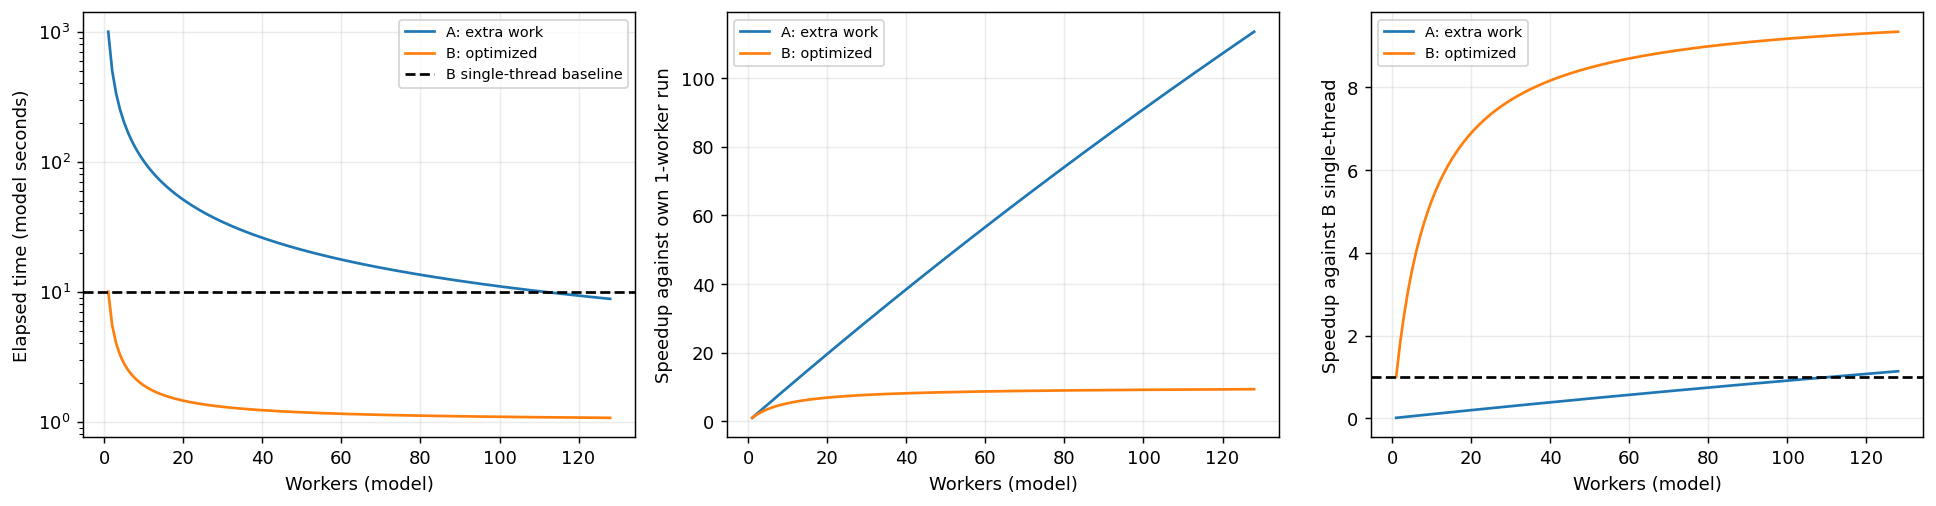

In [2]:
SERIAL = 1.0
USEFUL = 9.0
EXTRA_A = 990.0  # Try 0, 90, 990; this is artificial overhead.
EXTRA_B = 0.0
workers = np.arange(1, 129)
def model(p, extra):
    return SERIAL + (USEFUL + extra) / p
A = model(workers, EXTRA_A)
B = model(workers, EXTRA_B)
reference = model(1, EXTRA_B)
print('p    A seconds    B seconds    A self-speedup    B self-speedup    A/reference gain')
for p in (1, 2, 4, 16, 64, 128):
    a, b = model(p, EXTRA_A), model(p, EXTRA_B)
    print(f'{p:3d}  {a:10.3f}   {b:10.3f}    {A[0]/a:12.2f}     {B[0]/b:12.2f}       {reference/a:10.2f}')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for times, label in ((A, 'A: extra work'), (B, 'B: optimized')):
    ax[0].plot(workers, times, label=label)
    ax[1].plot(workers, times[0] / times, label=label)
    ax[2].plot(workers, reference / times, label=label)
ax[0].axhline(reference, color='black', linestyle='--', label='B single-thread baseline')
ax[0].set_yscale('log'); ax[0].set_ylabel('Elapsed time (model seconds)')
ax[1].set_ylabel('Speedup against own 1-worker run')
ax[2].axhline(1, color='black', linestyle='--'); ax[2].set_ylabel('Speedup against B single-thread')
for axis in ax:
    axis.set_xlabel('Workers (model)'); axis.grid(alpha=.25); axis.legend(fontsize=8)
plt.tight_layout(); show()

**读图：**左图越低越好，B 在每一种配置下都更快。中图 A 的自加速比更高，因为它最初特别慢。右图用共同基线后，B 的优势一目了然。

默认参数下，A 从 1000 秒降到约 8.8 秒，看起来加速超过 113 倍；B 从 10 秒降到约 1.07 秒，只加速约 9.3 倍。但用户实际等待的时间，B 始终更短。

优化后串行部分的**绝对时间没增加**，它在总时间中的占比增加了。因而继续增加工作单元时，剩余的加速空间减少。这就是这段论述的核心。

## 3. COST 是超过基线的门槛

在这个模型里，COST 可简化为满足 $T(p)<T_{reference}$ 的最小整数 $p$。真实论文说的是硬件配置，通常比一个整数复杂。

默认参数中，A 在 111 个工作单元时正好等于 10 秒，要到 112 个才严格超过 B 的单线程。B 在 2 个工作单元时就超过自己的单线程。

若实际只测了 1、2、4 个进程，均没有超过基线，只能写“在已测配置中未超过”。扩大配置可能交叉，也可能由于通信瓶颈始终无法交叉；这需要新的测量。

**因此，COST 衡量的是资源投入何时开始带来超过合理替代方案的收益。** 自加速比只是辅助解释；共同基线和交叉点才是评价中心。


In [3]:
for label, times in [('A', A), ('B', B)]:
    faster = workers[times < reference]
    print(label, 'model COST:', int(faster[0]) if len(faster) else 'not reached in tested model range')

A model COST: 112
B model COST: 2


## 4. PageRank 先算一个四节点小图

把排名想象为随机浏览者落在各页面上的概率。一轮更新：每个页面把自己的概率平均分给所有出边，再加上随机跳转。

$$r_{new}=\alpha P r+\left((1-\alpha)+\alpha\sum_{j\in D}r_j\right)\frac{\mathbf{1}}{n}$$

这里 $P_{ij}=1/outdegree(j)$ 表示边 $j\to i$ 的转移概率；$D$ 是没有出边的节点集合。它们的概率均匀分给所有节点，保证总和为 1。我们取 $\alpha=0.85$，初值为均匀分布。

下图关系用列表表示：A → B、C；B → C；C → A；D 没有出边。A、C 会反复收到链接，D 主要靠随机跳转得到概率。

Iteration  1: [0.303125 0.196875 0.409375 0.090625] sum= 1.0
Iteration  2: [0.404727 0.185586 0.35293  0.056758] sum= 1.0
Iteration  3: [0.349551 0.22157  0.379318 0.049561] sum= 1.0
Iteration  4: [0.370452 0.196591 0.384925 0.048032] sum= 1.0
Iteration  5: [0.374893 0.205149 0.372251 0.047707] sum= 1.0
Iteration 40: [0.369324 0.204582 0.378476 0.047619] sum= 1.0
Independent stationary solution: [0.36932353 0.20458155 0.37847587 0.04761905]


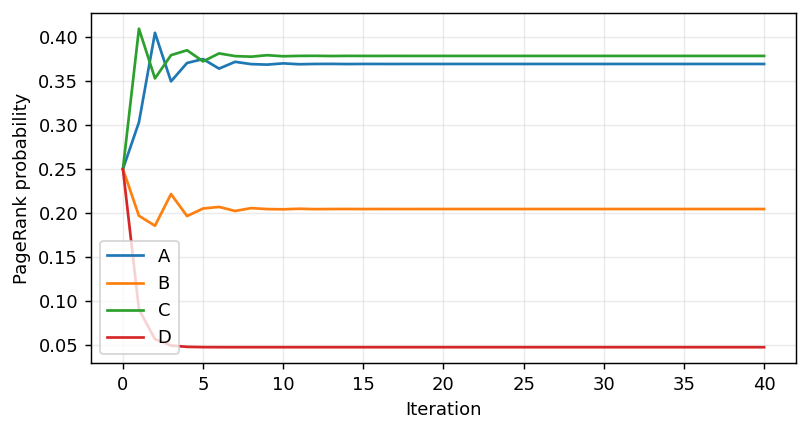

In [4]:
from scipy.sparse import csr_matrix
small_src = np.array([0, 0, 1, 2])
small_dst = np.array([1, 2, 2, 0])
small_out = np.bincount(small_src, minlength=4)
small_P = csr_matrix((1.0/small_out[small_src], (small_dst, small_src)), shape=(4, 4))
r = np.full(4, .25)
history = [r.copy()]
for step in range(40):
    r = .85*(small_P @ r + r[small_out == 0].sum()/4) + .15/4
    history.append(r.copy())
    if step < 5 or step == 39:
        print(f'Iteration {step+1:2d}:', np.round(r, 6), 'sum=', round(r.sum(), 12))
# Independent dense linear-system reference to check the equation itself.
transition = small_P.toarray()
transition[:, small_out == 0] = 1/4
exact = np.linalg.solve(np.eye(4) - .85*transition, np.full(4, .15/4))
np.testing.assert_allclose(r, exact, atol=1e-6, rtol=0)
print('Independent stationary solution:', exact)
plt.figure(figsize=(7, 3.5))
for i, name in enumerate('ABCD'):
    plt.plot(np.array(history)[:, i], label=name)
plt.xlabel('Iteration'); plt.ylabel('PageRank probability'); plt.legend(); plt.grid(alpha=.25); show()

## 5. 真实实验：同一个 PageRank，三种单线程实现

用固定随机种子生成一个有向多重图。允许重复边、自环，并保留一个无出边节点。重复边按多条链接处理；稀疏矩阵合并它们时会相加权重，因此三个实现语义一致。

1. Python 循环：逐边更新分数，容易理解，但每条边都会执行 Python 层操作。
2. NumPy：按数组取值，用 bincount 汇总目标节点收到的贡献。
3. SciPy CSR：把转移概率预先组织成稀疏矩阵，迭代时执行稀疏矩阵乘向量。

三者都执行相同的 20 轮更新。固定轮数避免不同停止条件干扰计时；20 轮是工作量定义，不保证任意图都已收敛。代码在旁边的 `pagerank_demo.py` 中。

**计时口径：**图生成和 CSR 构建单独记录；查询计时包含排名初始化。Python 实现还包含生成 Python 边列表的成本。各实现预热一次，然后计时三次取中位数。这里比较整体实现的效率，不能把差距单独归因于某一种缓存优化。

**这一节是本项目自写实现的对比，未复现作者的 Hilbert 布局优化。作者到底做了什么，见下一节 5.1。**


Nodes=8,000; edges=127,984; iterations=20; setup=0.001845s
Python edge loop  : median=0.096388s, samples=[0.096388 0.095258 0.098357]
NumPy bincount    : median=0.006615s, samples=[0.007584 0.006615 0.006557]
SciPy CSR         : median=0.001583s, samples=[0.001583 0.00159  0.00158 ]
Python edge loop max error: 1.3552527156068805e-19
NumPy bincount max error: 5.421010862427522e-20
SciPy CSR max error: 0.0
Python / CSR time ratio: 60.87632931085833


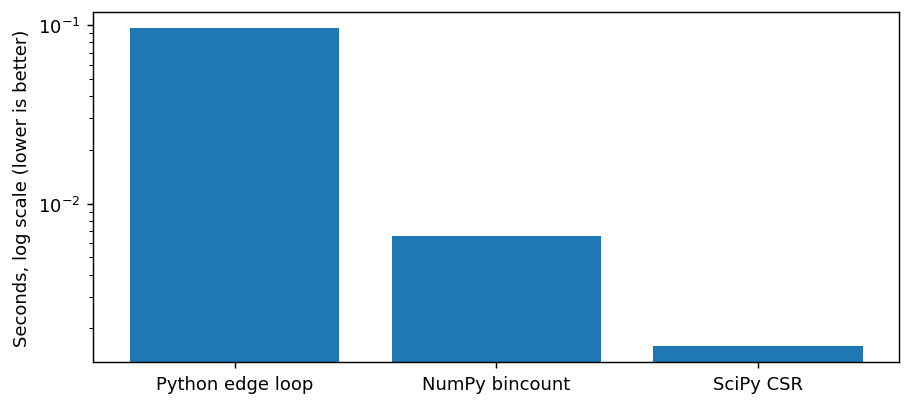

In [5]:
N = 8000
DEGREE = 16
ITERATIONS = 20
start = time.perf_counter()
src, dst, out, matrix = make_graph(N, DEGREE)
setup_s = time.perf_counter() - start
print(f'Nodes={N:,}; edges={len(src):,}; iterations={ITERATIONS}; setup={setup_s:.6f}s')
methods = {
    'Python edge loop': lambda: pagerank_python(src, dst, out, ITERATIONS),
    'NumPy bincount': lambda: pagerank_numpy(src, dst, out, ITERATIONS),
    'SciPy CSR': lambda: pagerank_sparse(matrix, out, ITERATIONS),
}
results = {}
ranks = {}
for label, fn in methods.items():
    seconds, rank, samples = timed(fn)
    results[label] = {'median_s': seconds, 'samples_s': samples}
    ranks[label] = rank
    print(f'{label:18s}: median={seconds:.6f}s, samples={np.round(samples, 6)}')
reference_rank = ranks['SciPy CSR']
for label, rank in ranks.items():
    np.testing.assert_allclose(rank, reference_rank, rtol=1e-11, atol=1e-13)
    assert np.all(rank >= 0)
    np.testing.assert_allclose(rank.sum(), 1.0, atol=1e-12)
    print(label, 'max error:', np.max(np.abs(rank-reference_rank)))
baseline_s = results['SciPy CSR']['median_s']
print('Python / CSR time ratio:', results['Python edge loop']['median_s']/baseline_s)
plt.figure(figsize=(8, 3.5))
plt.bar(results.keys(), [v['median_s'] for v in results.values()])
plt.yscale('log'); plt.ylabel('Seconds, log scale (lower is better)'); show()

### 5.1 论文到底怎样优化 PageRank？现在对照作者实现

之前的 demo 没有查看作者代码，也没有隔离复现原文的边布局优化；本节补上这个缺口。

已核对作者 **Rust 仓库提交 d5bef75f976ee5880811305621a2883d499f3e65** 的 `pagerank.rs`、`graph_iterator.rs`、`hilbert_curve.rs`、`to_hilbert.rs`；也阅读了 C# 仓库的 `SingleThreaded.cs`。本地只读副本和 MIT 许可证放在 `references/`。

| 层次 | 作者实现 | 本节如何处理 |
|---|---|---|
| 算法 | 固定 20 轮；每个源节点先算一次贡献，再沿边累加 | 保持更新结构；float32、零初值、重置值 0.15 |
| 边顺序 | 顶点顺序 vs Hilbert 顺序 | 同一批边、相同内核，只改顺序 |
| 边存储 | 顶点格式 `.nodes/.edges`；Hilbert 格式 `.upper/.lower`，高低位拆分 | 教学实验统一使用 uint32 源/目标数组，避免把格式变化混入顺序对比 |
| 执行开销 | Rust 通用 EdgeMapper；当前源码使用 unchecked 索引 | 两种顺序都运行同一个 Numba 编译内核，排除 Python 逐边解释开销 |
| I/O 与内存页 | 原文 C# 测量涉及无缓冲 I/O、2 MB 大页；Rust 使用 mmap 等路径 | 本节测 RAM 中数组，不模拟 SSD 或配置大页 |

**Hilbert 在改变什么？** 一条边 `(u,v)` 需要读源状态、更新目标状态。按 u 排序时源访问集中，目标可能分散；Hilbert 把二维 `(u,v)` 空间中附近的边安排在一起，在两端之间取得局部性平衡。它包含递归旋转和反射，**不是简单的 Morton/Z-order 比特交错**。

本项目的 Hilbert 编码已经与作者原始 `BytewiseHilbert` 在 260 个坐标上逐项核对，包括大坐标边界。作者原始 Rust 工程已编译，并在 4096 节点的本地图上执行了 vertex/hilbert 两种模式的 PageRank、标签传播和并查集。详见 `author_smoke_results.json`。这验证原程序可运行，不代表复现了论文的亿级边性能；PageRank 原 CLI 不输出最终排名，本节教学内核另与独立 SciPy 公式校验。

先用 8×8 网格看访问路径。横轴是源节点编号，纵轴是目标节点编号。

The SAME compiled kernel is used for both orders:
@njit(cache=True)
def paper_pagerank(src, dst, n, iterations=20):
    """Matches paper's zero initialization/reset=0.15 convention (not sum=1).

    One contribution per source per round, same compiled kernel for both orders.
    Test graphs have positive outdegree for every vertex, avoiding dangling ambiguity.
    """
    a = np.zeros(n, np.float32)
    b = np.zeros(n, np.float32)
    degree = np.zeros(n, np.float32)
    alpha = np.float32(.85)
    for e in range(len(src)):
        degree[src[e]] += np.float32(1)
    for _ in range(iterations):
        for v in range(n):
            b[v] = alpha * a[v] / degree[v] if degree[v] else np.float32(0)
            a[v] = np.float32(1) - alpha
        for e in range(len(src)):
            a[dst[e]] += b[src[e]]
    return a



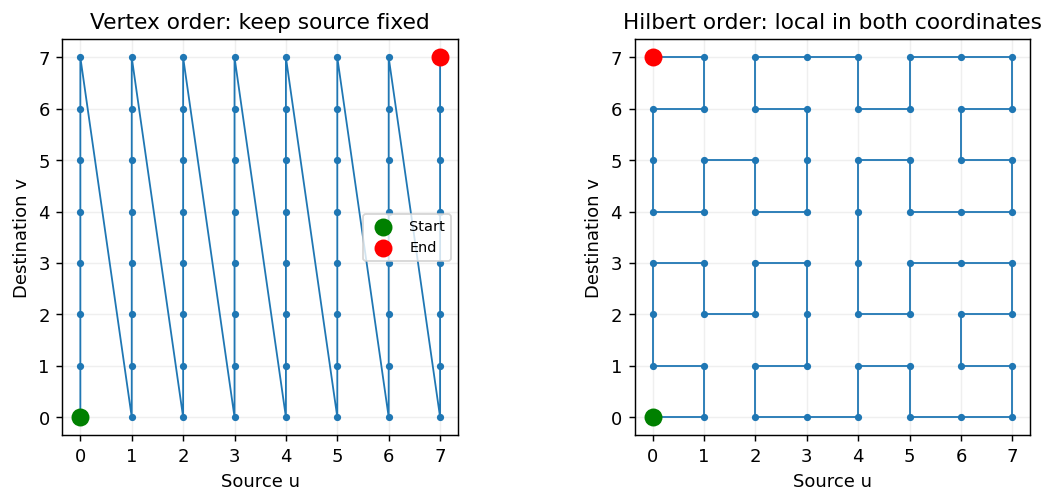

In [6]:
from paper_algorithms import hilbert_keys, paper_pagerank
import inspect
xy = np.array([(x,y) for x in range(8) for y in range(8)], dtype=np.uint32)
hi = np.argsort(hilbert_keys(xy[:,0].copy(), xy[:,1].copy()))
assert np.all(np.abs(np.diff(xy[hi].astype(int),axis=0)).sum(axis=1)==1)
fig,axes=plt.subplots(1,2,figsize=(9,4))
for ax,order,title in [(axes[0],np.arange(64),'Vertex order: keep source fixed'),(axes[1],hi,'Hilbert order: local in both coordinates')]:
    points=xy[order]
    ax.plot(points[:,0],points[:,1],'-o',markersize=3,linewidth=1)
    ax.scatter(*points[0],s=80,color='green',label='Start',zorder=4)
    ax.scatter(*points[-1],s=80,color='red',label='End',zorder=4)
    ax.set(xlabel='Source u',ylabel='Destination v',title=title,aspect='equal')
    ax.set_xticks(range(8));ax.set_yticks(range(8));ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.tight_layout();show()
print('The SAME compiled kernel is used for both orders:')
print(inspect.getsource(paper_pagerank.py_func))

**本节的结果语义与前面的概率版 PageRank 分开。** 作者版本从零开始，重置值为 0.15，并非归一化到总和为 1。本节每个节点都有 8 条出边，没有悬挂节点；两种顺序执行相同 20 轮，并与同样初值/重置规则的 float64 稀疏矩阵实现比较。前面带悬挂节点的概率版与本节不能直接混用耗时来算 COST。

计时包括数组初始化、出度计算和 20 轮；排除 Numba 首次编译。每种顺序预热，交替测量 5 次取中位数。Hilbert 编码、排序、重排的准备时间单列。只比较两种顺序的稳态循环，会遗漏一次性任务的重要成本。

这里读取已保存的本机实测，重跑完整实验用 `python benchmark_paper.py`。

nodes       vertex ms    Hilbert ms   gain     reorder ms   total first Hilbert ms   repeated 20-round jobs to amortize
    8,192         0.77         0.75   1.03x         5.24                     5.99 238
  262,144        47.19        24.15   1.95x       210.82                   234.96 10
1,048,576       200.19       126.08   1.59x      1037.98                  1164.06 15


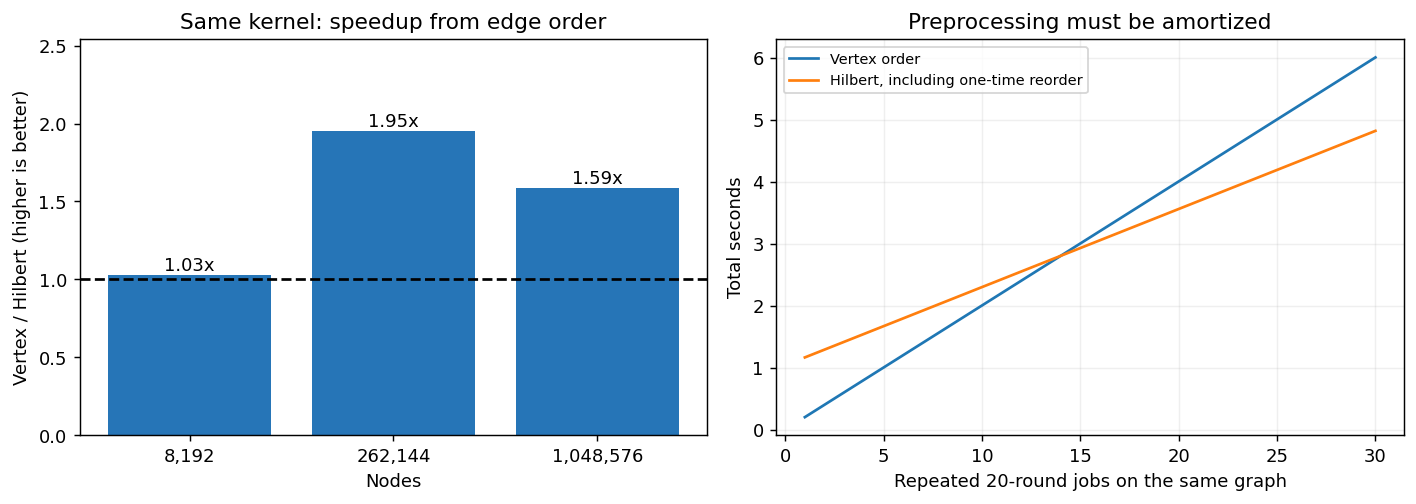

In [7]:
layout = json.loads(Path('layout_results.json').read_text())
print('nodes       vertex ms    Hilbert ms   gain     reorder ms   total first Hilbert ms   repeated 20-round jobs to amortize')
for c in layout['cases']:
    tv=c['vertex']['median_s'];th=c['hilbert']['median_s'];prep=c['preprocess_s']
    jobs=int(np.floor(prep/(tv-th))+1) if tv>th else None
    print(f"{c['nodes']:9,d} {tv*1000:12.2f} {th*1000:12.2f} {tv/th:6.2f}x {prep*1000:12.2f} {(prep+th)*1000:24.2f} {jobs}")
fig,axes=plt.subplots(1,2,figsize=(11,4))
cs=layout['cases'];x=np.arange(len(cs))
gain=[c['vertex']['median_s']/c['hilbert']['median_s'] for c in cs]
bars=axes[0].bar(x,gain,color='#2675B7');axes[0].bar_label(bars,fmt='%.2fx')
axes[0].axhline(1,color='black',linestyle='--');axes[0].set_ylim(0,max(gain)*1.3)
axes[0].set_xticks(x,[f"{c['nodes']:,}" for c in cs]);axes[0].set_title('Same kernel: speedup from edge order');axes[0].set_ylabel('Vertex / Hilbert (higher is better)');axes[0].set_xlabel('Nodes')
c=cs[-1];tv=c['vertex']['median_s'];th=c['hilbert']['median_s'];prep=c['preprocess_s']
jobs=np.arange(1,31)
axes[1].plot(jobs,tv*jobs,label='Vertex order')
axes[1].plot(jobs,prep+th*jobs,label='Hilbert, including one-time reorder')
axes[1].set(xlabel='Repeated 20-round jobs on the same graph',ylabel='Total seconds',title='Preprocessing must be amortized')
axes[1].legend(fontsize=8);axes[1].grid(alpha=.2)
plt.tight_layout();show()

**这组实测说明：** 在 1,048,576 节点、8,388,608 条边上，改变顺序使 20 轮从约 200 ms 降至 126 ms，约 1.59 倍加速；但重排约需 1.04 秒，同一张图约重复 15 次这样的任务才摊回准备成本。小图的收益很小，接近计时噪声。

这支持“同一算法的数据布局也会影响基线效率”，没有重现原论文全部存储格式与大页优化，也没有硬件计数器证据将收益精确拆成 cache/TLB 占比。**COST 要求认真构造基线，同时也要求公平计入预处理；不能只选择有利的一段时间。**

## 6. 真实实验：原版为什么慢，优化后能否加速？

**先看结论：之前的进程池实现有大量可避免的传输开销。去掉这些开销并增大图之后，bincount 的 4 进程版本获得约 3.7 倍加速，CSR 的 4 线程版本获得约 2.3 倍加速。** 下面保留原版结果作为对照，再逐步解释改进。

### 6.1 原版：每轮传图的 bincount 进程池

这里的子进程执行的是 **NumPy bincount，不是 Python 逐边循环**：

```python
incoming = np.bincount(dst_chunk,
                       weights=rank[src_chunk] / out[src_chunk],
                       minlength=n)
```

`bincount` 按目标节点编号，把各条边的贡献加起来。主进程将各子进程返回的数组相加，再更新下一轮的排名。

原版每轮都通过进程间通信发送边分片、出度、排名，再收回完整贡献数组。即使只启动 1 个子进程，这些传输仍然存在。因此 **“进程池 1 个子进程”与“主进程直接调用 bincount”是两个不同基线**。图中的 CSR 横线是另一个更有效的单线程实现。

```text
主进程序列化并发送数据 → 子进程 bincount → 返回贡献数组 → 主进程归并
                          每轮重复，共 20 轮
```

先在 8000 个节点的小图上运行原版。增加进程后变化很小，说明这个具体实现没有明显收益；下一小节会通过逐项改动找出原因。

Mac 使用 spawn 启动子进程，所以工作函数位于独立模块中。启动/预热与查询计时分开报告；查询计时包含每轮传输。横轴是子进程数，主进程也参与计算，并非独占 CPU 核数。


workers=1; startup=0.2312s; query median=0.035169s; lifecycle (3 queries)=0.3570s; PIDs=[53038]
workers=2; startup=0.2171s; query median=0.030994s; lifecycle (3 queries)=0.3279s; PIDs=[53039, 53040]
workers=4; startup=0.2341s; query median=0.030724s; lifecycle (3 queries)=0.3534s; PIDs=[53041, 53042, 53043, 53044]

workers | self speedup | speedup vs single-thread CSR | relative elapsed time
      1 |        1.000 |                        0.045 |                 22.21x
      2 |        1.135 |                        0.051 |                 19.58x
      4 |        1.145 |                        0.052 |                 19.40x
First measured process count beating CSR: None in {1, 2, 4}; no claim about larger configurations.


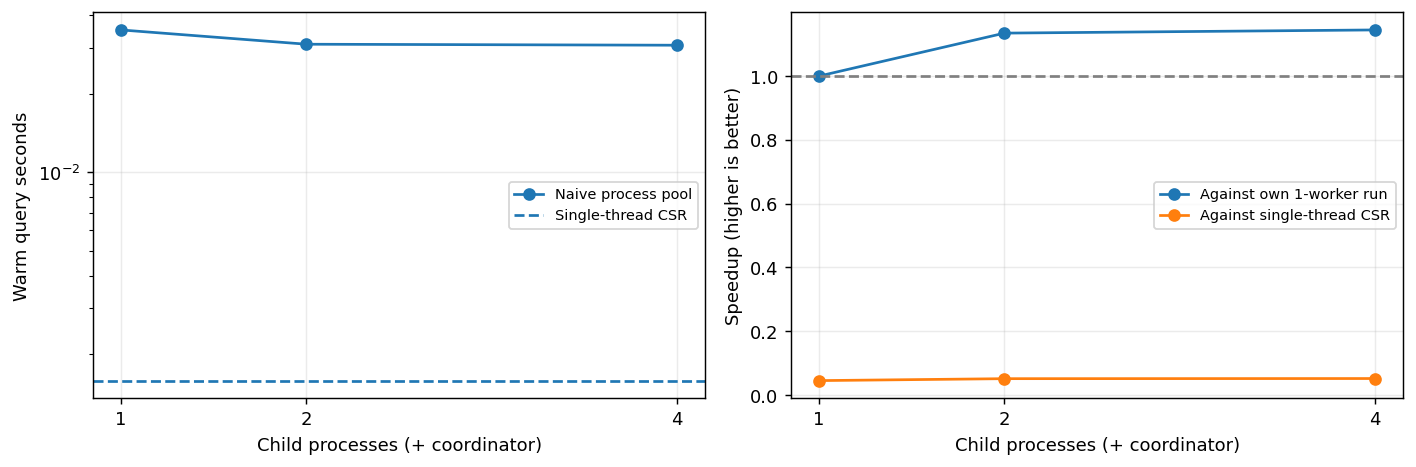

In [8]:
parallel_results = []
for p in (1, 2, 4):
    stats, rank = parallel_trial(src, dst, out, p, ITERATIONS)
    np.testing.assert_allclose(rank, reference_rank, rtol=1e-11, atol=1e-13)
    parallel_results.append(stats)
    print(f"workers={p}; startup={stats['startup_s']:.4f}s; query median={stats['query_s']:.6f}s; "
          f"lifecycle (3 queries)={stats['lifecycle_s']:.4f}s; PIDs={stats['observed_pids']}")
one_worker_s = parallel_results[0]['query_s']
print('\nworkers | self speedup | speedup vs single-thread CSR | relative elapsed time')
for stats in parallel_results:
    t = stats['query_s']
    print(f"{stats['workers']:7d} | {one_worker_s/t:12.3f} | {baseline_s/t:28.3f} | {t/baseline_s:21.2f}x")
ps = [x['workers'] for x in parallel_results]
ts = [x['query_s'] for x in parallel_results]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(ps, ts, 'o-', label='Naive process pool')
axes[0].axhline(baseline_s, linestyle='--', label='Single-thread CSR')
axes[0].set_ylabel('Warm query seconds'); axes[0].set_yscale('log')
axes[1].plot(ps, one_worker_s/np.array(ts), 'o-', label='Against own 1-worker run')
axes[1].plot(ps, baseline_s/np.array(ts), 'o-', label='Against single-thread CSR')
axes[1].axhline(1, color='gray', linestyle='--'); axes[1].set_ylabel('Speedup (higher is better)')
for axis in axes:
    axis.set_xlabel('Child processes (+ coordinator)'); axis.set_xticks(ps); axis.legend(fontsize=8); axis.grid(alpha=.25)
plt.tight_layout(); show()
beats = [s['workers'] for s in parallel_results if s['query_s'] < baseline_s]
print('First measured process count beating CSR:', min(beats) if beats else 'None in {1, 2, 4}; no claim about larger configurations.')
report = {'platform': platform.platform(), 'python': sys.version.split()[0],
          'numpy': np.__version__, 'scipy': scipy.__version__, 'nodes': N, 'edges': len(src),
          'iterations': ITERATIONS, 'setup_s': setup_s, 'single_thread': results,
          'parallel': parallel_results, 'baseline': 'SciPy CSR'}
Path('results.json').write_text(json.dumps(report, indent=2))

### 6.2 逐项优化：先减少传输，再扩大图

上一节每轮把 `src`、`dst`、`out`、`rank` 都通过进程间通信发送一遍。图的边和出度不会随轮次变化，却重复传输 20 次。这是可避免的实现开销。

这里新增四组对照，图、随机种子、20 轮更新保持相同：

| 名称 | 计算内核 | 图数据 | 每轮交换什么 |
|---|---|---|---|
| naive | bincount | 每轮发送边分片 | 边、出度、排名、完整贡献数组 |
| resident | bincount | 图常驻共享内存 | 排名、完整贡献数组 |
| shared | bincount | 图常驻共享内存 | 仅任务编号和计时，排名/贡献走共享内存 |
| csr_threads | CSR 矩阵向量乘 | CSR 按目标行划分，线程共享地址空间 | 线程返回各自的输出行，拼接即可 |

前三组逐步去掉进程间传输，比较它们可判断这些设计改变的效果。第四组额外改变了数据结构和分区方式，展示更有效的并行设计；它的加速比应与单线程 CSR 比较。

CSR 按目标节点分区后，每个输出节点只由一个任务负责。它不需要像按边分区的 bincount 那样，生成 p 个长度 n 的贡献数组后再相加。这既减少重复输出，也改善了组织计算的方式。

**计时方法：**每个配置先跑一次完整查询预热，再重复 5 次取中位数。图准备、共享缓冲区准备、池启动和预热排除在查询耗时之外，单独保存在 `setup_and_warmup_s`。每个配置都检查结果与单线程 CSR 一致。没有硬件性能计数器数据，不能由这些计时直接判定内存带宽饱和。

诊断实验由 `python diagnose_parallel.py` 单独执行。下面读取保存的 `diagnosis_results.json`，正常重跑 notebook 不会重新执行整套较大的诊断。

**新图怎么读：** 第一张图只展示最大的图，每个方案一个面板，纵轴统一使用线性的加速比。蓝柱为该方案自身的 `T(1)/T(p)`；橙柱为直接串行内核的耗时除以并行耗时。灰色虚线表示理想的自身加速比 1、2、4 倍。每根柱都直接标出数值，超过 1 倍才表示比相应基线快。

前三个面板的橙柱使用直接单进程 NumPy bincount 为基线；CSR 面板使用直接单线程 CSR。蓝柱的 1-worker 包含池内调度成本，橙柱的直接串行基线没有这些成本。不同面板的加速比不用于判断谁的绝对时间最短，耗时见下一节表格。

第二张图固定为 4 个工作单元，比较三种图规模相对于直接串行内核的加速比。红色小于 1，绿色大于 1。重点看 fully shared 一列随规模从约 1.07 倍到 1.87 倍再到 3.68 倍的变化。


Measured on: macOS-26.6.1-arm64-arm-64bit-Mach-O
Main chart: 400,000 nodes, 6,399,984 edges, 20 iterations
Blue = same implementation T(1) / T(p). Orange = direct serial kernel / T(p).
Direct serial baseline: NumPy for first 3 panels; CSR for last panel.
Higher is better; 1x = break-even. Startup/preparation excluded.
naive       : times ms=[5341.6 3294.  2392.5], self=[1.   1.62 2.23], direct=[0.1  0.17 0.23]
resident    : times ms=[686.9 504.3 572.5], self=[1.   1.36 1.2 ], direct=[0.8  1.08 0.96]
shared      : times ms=[543.5 259.5 148.8], self=[1.   2.09 3.65], direct=[1.01 2.11 3.68]
csr_threads : times ms=[121.5  75.4  49.7], self=[1.   1.61 2.45], direct=[0.94 1.51 2.29]


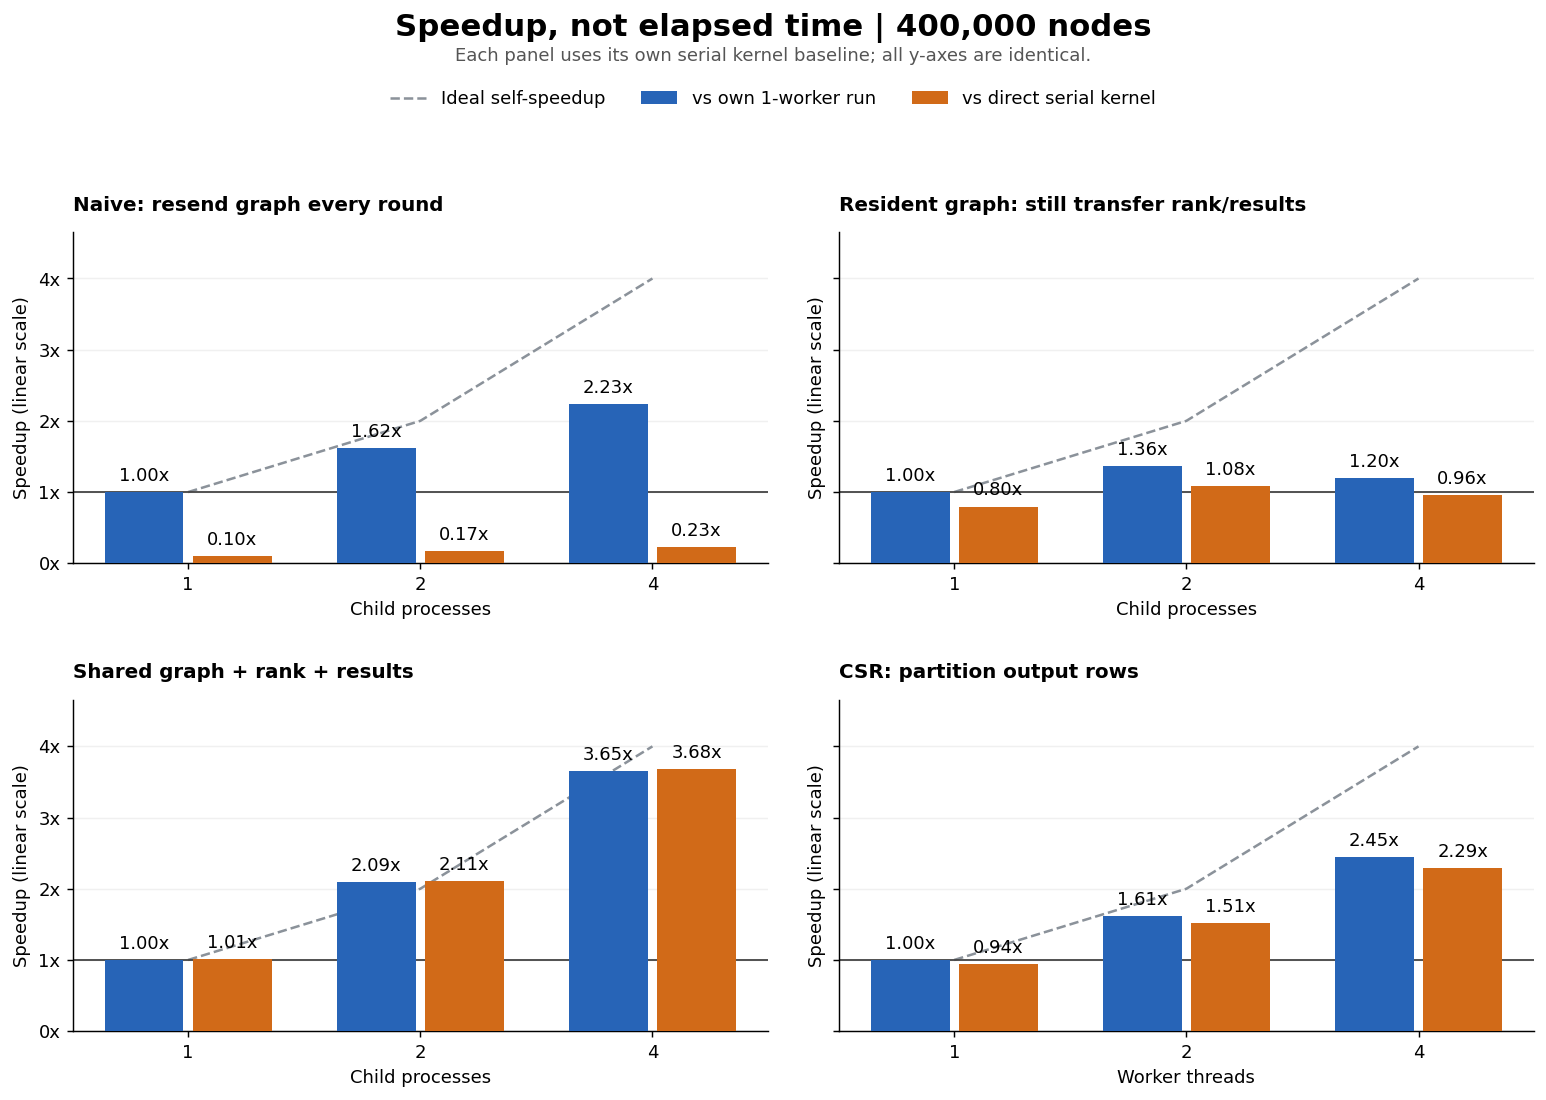

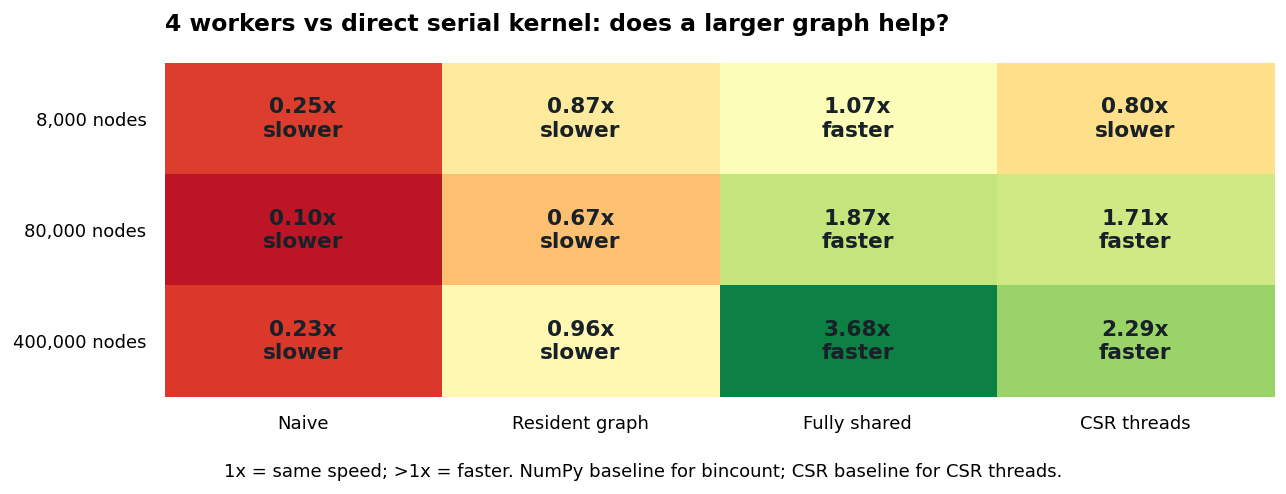

In [9]:
from matplotlib.ticker import MultipleLocator, FuncFormatter

diagnosis = json.loads(Path('diagnosis_results.json').read_text())
modes = ('naive', 'resident', 'shared', 'csr_threads')
titles = {'naive': 'Naive: resend graph every round',
          'resident': 'Resident graph: still transfer rank/results',
          'shared': 'Shared graph + rank + results',
          'csr_threads': 'CSR: partition output rows'}
case = max(diagnosis['cases'], key=lambda c: c['nodes'])
print(f"Measured on: {diagnosis['platform']}")
print(f"Main chart: {case['nodes']:,} nodes, {case['edges']:,} edges, 20 iterations")
print('Blue = same implementation T(1) / T(p). Orange = direct serial kernel / T(p).')
print('Direct serial baseline: NumPy for first 3 panels; CSR for last panel.')
print('Higher is better; 1x = break-even. Startup/preparation excluded.')

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
blue, orange = '#2764B7', '#D16A18'
for ax, mode in zip(axes.flat, modes):
    runs = sorted([r for r in case['runs'] if r['mode']==mode], key=lambda r:r['workers'])
    ps = np.array([r['workers'] for r in runs])
    times = np.array([r['median_s'] for r in runs])
    own = next(r['median_s'] for r in runs if r['workers']==1)
    baseline_key = 'csr' if mode=='csr_threads' else 'numpy'
    direct = case[baseline_key]['median_s']
    x = np.arange(len(ps))
    for offset, values, color, label in [(-.19, own/times, blue, 'vs own 1-worker run'),
                                           (.19, direct/times, orange, 'vs direct serial kernel')]:
        bars = ax.bar(x+offset, values, width=.34, color=color, label=label, zorder=3)
        ax.bar_label(bars, labels=[f'{v:.2f}x' for v in values], padding=4, fontsize=10)
    ax.plot(x, ps, '--', color='#8B929A', linewidth=1.4, label='Ideal self-speedup', zorder=2)
    ax.axhline(1, color='#444444', linewidth=1, zorder=2)
    ax.set_ylim(0, 4.65)
    ax.set_xticks(x, [str(p) for p in ps])
    ax.set_xlabel('Worker threads' if mode=='csr_threads' else 'Child processes')
    ax.set_title(titles[mode], loc='left', fontsize=11, fontweight='bold', pad=12)
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v,_: f'{v:.0f}x'))
    ax.set_ylabel('Speedup (linear scale)')
    ax.grid(axis='y', alpha=.18, zorder=0)
    ax.spines[['top','right']].set_visible(False)
    print(f"{mode:12s}: times ms={np.round(times*1000,1)}, self={np.round(own/times,2)}, direct={np.round(direct/times,2)}")
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5,.935), ncol=3, frameon=False, fontsize=10)
fig.suptitle(f"Speedup, not elapsed time | {case['nodes']:,} nodes", fontsize=17, fontweight='bold', y=.99)
fig.text(.5,.947, 'Each panel uses its own serial kernel baseline; all y-axes are identical.', ha='center',fontsize=10,color='#555555')
fig.tight_layout(rect=(0,0,1,.89),h_pad=2.4,w_pad=2.2)
show()

# At four workers, compare graph sizes with explicit speedup numbers.
values=[]
for c in diagnosis['cases']:
    row=[]
    for mode in modes:
        run=next(r for r in c['runs'] if r['mode']==mode and r['workers']==4)
        base=c['csr' if mode=='csr_threads' else 'numpy']['median_s']
        row.append(base/run['median_s'])
    values.append(row)
values=np.array(values)
from matplotlib.colors import TwoSlopeNorm
fig,ax=plt.subplots(figsize=(10,3.8))
norm=TwoSlopeNorm(vmin=0,vcenter=1,vmax=max(4,float(values.max())))
ax.imshow(values,cmap='RdYlGn',norm=norm,aspect='auto')
ax.set_xticks(range(4),['Naive','Resident graph','Fully shared','CSR threads'])
ax.set_yticks(range(len(values)),[f"{c['nodes']:,} nodes" for c in diagnosis['cases']])
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        v=values[row,col]
        phrase='faster' if v>1 else 'slower'
        ax.text(col,row,f'{v:.2f}x\n{phrase}',ha='center',va='center',fontsize=12,fontweight='bold',color='#182028')
ax.set_title('4 workers vs direct serial kernel: does a larger graph help?',loc='left',fontsize=13,fontweight='bold',pad=18)
ax.tick_params(length=0,pad=10)
ax.spines[:].set_visible(False)
fig.text(.5,.02,'1x = same speed; >1x = faster. NumPy baseline for bincount; CSR baseline for CSR threads.',ha='center',fontsize=10)
plt.tight_layout(rect=(0,.07,1,1)); show()


### 6.3 实测结果：问题出在什么地方？

以下是保存的诊断实测：**400000 个节点、6399984 条边、20 轮**。每个配置预热一次，重复五次取中位数，计算结果与单线程 CSR 一致。时间不含准备和启动；完整样本保存在 diagnosis_results.json。

| 实现 | 20 轮耗时 |
|---|---:|
| 直接单进程 bincount | 547.0 ms |
| 原版 4 进程：每轮发送图 | 2,392.5 ms |
| 4 进程：图常驻共享内存 | 572.5 ms |
| 4 进程：图、排名、输出均共享 | 148.8 ms |
| 直接单线程 CSR | 114.0 ms |
| 按输出行分区的 4 线程 CSR | 49.7 ms |

**原因一：不变的图被反复传输。** 这个规模的 src、dst 两个 int64 数组合计约 102 MB，重复 20 轮就是约 2 GB 的原始边数据，尚未计算出度、排名、输出和序列化开销。保持 bincount 计算不变，只把图常驻共享内存，4 进程耗时从约 2392 ms 降到 573 ms。

**原因二：排名和输出仍要来回序列化。** 进一步共享排名与贡献缓冲区后，主进程仅发送任务编号并等待完成，耗时从约 573 ms 降到 149 ms。共享内存仍然需要读写数据和同步，它消除的是这些数组的跨进程序列化传输。

**原因三：小图计算量太少，固定开销占比高。** 8000 个节点时，直接 bincount 约 8.0 ms，共享内存 4 进程约 7.5 ms；400000 个节点时，则从约 547 ms 降到 149 ms，约 3.7 倍加速。原来的小图无法充分摊薄调度与同步成本。

**CSR 的进一步收益：** 按目标节点划分矩阵行，每个线程负责一段互不重叠的输出。最后拼接即可，避免生成多份长度 n 的贡献数组再求和。4 线程约 50 ms，比直接单线程的 114 ms 快约 2.3 倍。这同时改变了数据结构和分区方式，应以 CSR 自己的单线程为并行加速基线。

**回看图：** 大图中原版 naive 的蓝柱显示自身约 2.23 倍加速，橙柱却只有约 0.23 倍，说明相对直接串行 bincount 仍慢。fully shared 的蓝柱约 3.65 倍、橙柱约 3.68 倍，显示去掉传输后已经获得实质收益。两者略有差异，是池中单工作单元与直接串行调用的耗时不同。CSR 的橙柱约 2.29 倍。第二张图则显示小图的固定开销更难摊薄。

这些图只用保存的同一批测量重新计算比值，没有重跑或改动原始耗时。绝对耗时仍见上表，CSR 单线程仍快于 fully shared 的 4 进程。


### 如何解读拆分计时

`dispatch_wait_s` 是主进程从准备/提交任务到收到所有结果的耗时，包含传输、排队、子进程计算和等待。`reduce_s` 是主进程求和或拼接，`update_s` 是阻尼和悬挂节点处理。

`max_worker_compute_sum_s` 是每轮各任务纯 bincount 计算时间的最大值，再跨轮求和。它描述理想同时执行时的计算关键路径估计；任务可能并非同时开始，因此不能把它从等待时间中减掉后声称剩下的全是通信。各列也独立取中位数，不要求相加恰好等于总耗时。

这些消融比较能确认：去掉图的反复传输，以及去掉排名/输出的序列化，是否改善性能。它们不能独立分离 CPU 缓存、调度、分配与内存带宽各占多少。

**修正此前的结论表达：**最初的多进程实现过于粗糙，无法用它判断 PageRank 的并行潜力。应先去掉可避免的开销，再同时比较同实现的扩展性，以及相对于有效单线程基线的收益。上面的结果以当前保存的实测为准，进程和线程数都不是独占 CPU 核数。


### 6.4 回到 COST：超过合理单线程了吗？需要什么配置？

前面 6.2 的自身加速比帮助诊断实现，但论文最终要问的是这一节的问题。

对原有概率版 PageRank 实验，**现在统一选直接单线程 CSR 为合理基线**。这批结果使用相同图、悬挂节点处理和 20 轮迭代；不把 5.1 的另一套语义/数据混进来。

下表的每个比值都为 `直接单线程 CSR 时间 / 当前系统时间`。**超过 1 才算越过基线。** “首次已测配置”只在 {1,2,4} 内寻找。线程和进程的协调开销不同，表中是工作单元配置，不声称等价于严格核心数。

这也解释为什么不能给引入大量可并行开销的系统好评：一个方案自身快了 2 倍，却仍只有有效基线速度的 0.05 倍时，它还没有为这个任务带来绝对性能收益。

COMMON baseline: direct single-thread CSR. Ratio > 1 beats baseline.
Nodes     scheme          gain@1   gain@2   gain@4    first measured faster configuration
  8,000 naive              0.04x    0.05x    0.05x    NOT reached among 1, 2, 4
  8,000 resident           0.15x    0.20x    0.18x    NOT reached among 1, 2, 4
  8,000 shared             0.17x    0.24x    0.22x    NOT reached among 1, 2, 4
  8,000 csr_threads        0.71x    0.96x    0.80x    NOT reached among 1, 2, 4
 80,000 naive              0.04x    0.03x    0.02x    NOT reached among 1, 2, 4
 80,000 resident           0.17x    0.21x    0.17x    NOT reached among 1, 2, 4
 80,000 shared             0.21x    0.28x    0.48x    NOT reached among 1, 2, 4
 80,000 csr_threads        0.91x    1.30x    1.71x    2 workers
400,000 naive              0.02x    0.03x    0.05x    NOT reached among 1, 2, 4
400,000 resident           0.17x    0.23x    0.20x    NOT reached among 1, 2, 4
400,000 shared             0.21x    0.44x    0.77x    NOT

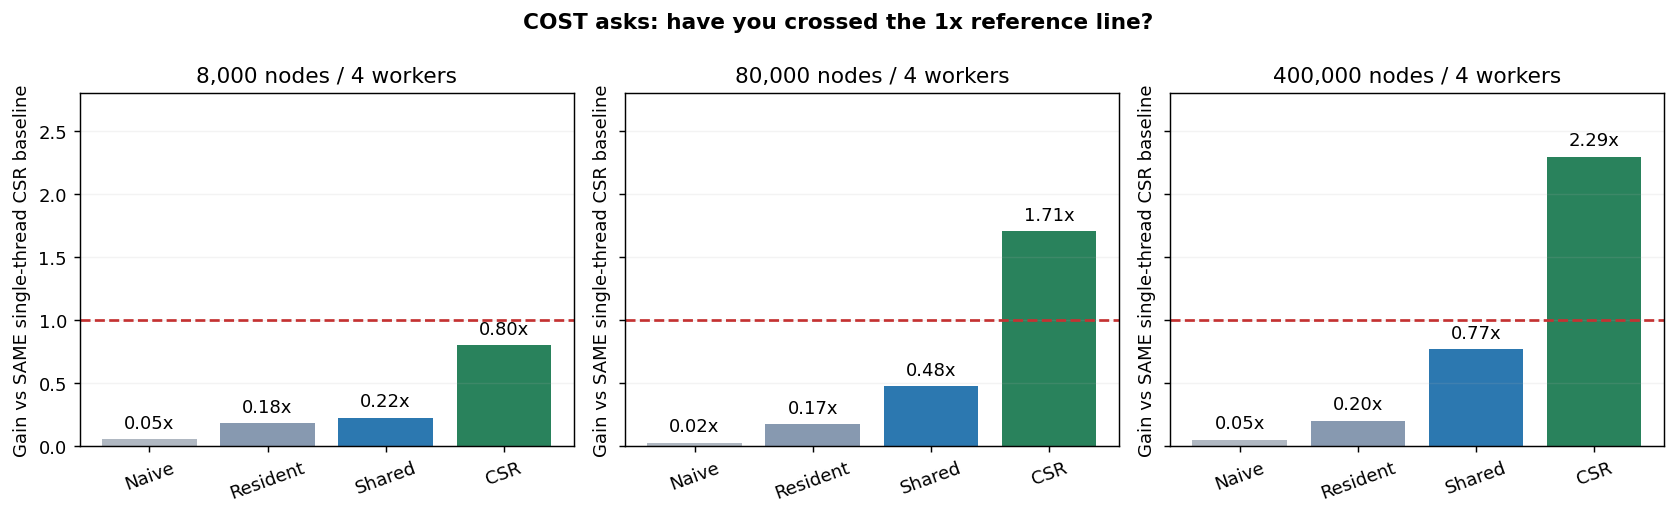

In [10]:
diagnosis = json.loads(Path('diagnosis_results.json').read_text())
print('COMMON baseline: direct single-thread CSR. Ratio > 1 beats baseline.')
print('Nodes     scheme          gain@1   gain@2   gain@4    first measured faster configuration')
for c in diagnosis['cases']:
    base=c['csr']['median_s']
    for mode in ('naive','resident','shared','csr_threads'):
        runs=sorted([r for r in c['runs'] if r['mode']==mode],key=lambda r:r['workers'])
        gains=[base/r['median_s'] for r in runs]
        beats=[r['workers'] for r in runs if r['median_s']<base]
        answer=f'{min(beats)} workers' if beats else 'NOT reached among 1, 2, 4'
        print(f"{c['nodes']:7,d} {mode:15s} "+' '.join(f'{g:7.2f}x' for g in gains)+'    '+answer)
fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,c in zip(axes,diagnosis['cases']):
    modes=('naive','resident','shared','csr_threads')
    g=[c['csr']['median_s']/next(r['median_s'] for r in c['runs'] if r['mode']==m and r['workers']==4) for m in modes]
    bars=ax.bar(range(4),g,color=['#B0B8C2','#8799B0','#2C78B0','#29825C'])
    ax.bar_label(bars,labels=[f'{x:.2f}x' for x in g],padding=4)
    ax.axhline(1,color='#C43232',linestyle='--',linewidth=1.5)
    ax.set_xticks(range(4),['Naive','Resident','Shared','CSR'],rotation=20)
    ax.set_title(f"{c['nodes']:,} nodes / 4 workers")
    ax.set_ylim(0,2.8);ax.set_ylabel('Gain vs SAME single-thread CSR baseline')
    ax.grid(axis='y',alpha=.15)
fig.suptitle('COST asks: have you crossed the 1x reference line?',fontweight='bold')
plt.tight_layout();show()

**本机观测门槛：** 在这批已测配置中，三种 bincount 并行实现都没有超过单线程 CSR；CSR 线程池在 8 万和 40 万节点上，首次测试到超过基线的配置是 2 线程；8000 节点上没有超过。

例如大图中 fully shared 的“相对直接 bincount”加速比为 3.68，但相对 CSR 只有约 0.77，仍未越过共同基线。CSR 4 线程相对同一基线约 2.29，才是已经取得的绝对性能收益。

**这不是要求系统永远只用一个线程，而是要求多用资源能够说明收益。** 若某个平台还提供容错、容量和运维能力，应另行评价这些能力的价值；COST 负责把固定任务上的性能投入与收益说清楚。

## 7. 回答最初的问题

COST 是**系统超过一个实现得当的单线程替代方案所需的配置**。它避免把“给多余工作增加并行度”误认成对用户有用的性能进步。

这份 notebook 的证据分成三层：

1. **数学模型：** 解释自身加速比为什么可能奖励低效实现。
2. **作者 PageRank 布局方法的教学移植：** 相同算法仍能因边顺序变快；有效基线需要认真构建，准备成本也要算。
3. **本机并行实现：** 去掉传输开销后确实有扩展收益，但用共同 CSR 基线衡量，只有部分配置真正越过基线。

连通分量的下一层问题更深入：**如果系统采用的算法本来就做了更多工作呢？** 见 [cost_connected_components.ipynb](cost_connected_components.ipynb)：同一连通性任务，标签传播可能反复扫边，并查集只扫描一次边。具体哪个更快仍与图结构、顺序和实现有关，因此要用结果验证基线选择。

## 8. 回到论文：结论到底是什么？

**COST 的主张是：评价可扩展系统时，要用一个合理的简单实现检查它的绝对性能。** 扩展曲线回答“加资源是否变快”；单线程基线回答“这个复杂系统提供了多少实际收益”。两个问题都值得回答。

原文进一步展示了两类改进方向：同一个算法可以改善数据布局；同一个任务也可以改用工作量更少的算法。比如连通分量任务中，标签传播与并查集是在解决同一问题，但工作量很不同。本 notebook 的 PageRank 保持算法相同；作者布局优化见 5.1 节，算法选择实验见配套的 cost_connected_components.ipynb。

因此它对工程选择的建议是：先把一个合理的简单方案量清楚，再判断额外资源带来的收益。大容量、吞吐、可用性、共享访问等需求仍可能使分布式系统成为合适选择；COST 衡量的是固定任务上的性能门槛，而非所有功能的总价值。

**与 DuckDB 那篇的关系：**2019 年 DuckDB 论文提出把分析数据库嵌入应用，围绕批量执行、数据交换和宿主资源使用做设计。它主要是架构与演示论文。两篇放在一起，可以理解为：COST 提醒你识别多余工作，DuckDB 提供一种减少分析场景中系统开销的架构方向。这是阅读上的联系，不是本 demo 已经验证 DuckDB 的性能。

[DuckDB 原文](https://ir.cwi.nl/pub/28800/28800.pdf)

### 用自己的话回答这三个问题

- A 单线程 1000 秒，100 个工作单元 20 秒；B 单线程 10 秒。A 加速了多少？相对 B 又怎样？
- 删除可并行的额外工作后，哪些时间减少了？为什么自加速比可能变小？
- 一个并行方案用了 4 个子进程仍比 CSR 慢，下一步应先检查哪些开销？

参考答案：50 倍，但仍比 B 慢 2 倍；绝对耗时减少，而固定串行部分的占比增加；检查序列化、数据复制、同步、分区、内存带宽与总工作量，并以相同结果和计时口径重新测量。